## Wu et al. (2014) from the Effective Dimensionality Theory

First principle prediction of the motor-variability results of Wu et al. (2014, *Nature Neuroscience*,
Fig. 1) with the our theory.

### Theory: KL term from measured variability

**Prior and target.** The prior over policies is $q_0(\theta) = \mathcal{N}(0, \Sigma)$
with $\theta \in \mathbb{R}^k$. A task has target $a^* = d\,u$, where $u$ is a unit
vector (the task direction) and $d$ is the target distance.

**Measurement.** For a given task we measure the variance along its task direction,

$$v = u^\top \Sigma\, u.$$

**Point-mass posterior.** Take the learned posterior to be a point mass at the target,
$q^* = \delta_{a^*}$. Against a continuous prior, $\mathrm{KL}(q^*\Vert q_0)$ is
infinite; as in the discrete case (Eq. 9 of the theory), we approximate it by the
negative log prior density at the target.

$$\mathrm{KL}(q^*\Vert q_0) \approx -\log_2 q_0(d\,u)
= \frac{d^2}{2\ln 2}\, u^\top \Sigma^{-1} u + \frac{1}{2}\log_2\det\Sigma + \frac{k}{2}\log_2 2\pi.$$

**Assumption.** The task direction is uncorrelated with the orthogonal directions,
$u^\top \Sigma\, w = 0$ for every $w \perp u$, so that $u^\top \Sigma^{-1} u = 1/v$.  
This does correspond to the setup of the task.

**Leading term.** The remaining two terms, $\frac{1}{2}\log_2\det\Sigma$ and
$\frac{k}{2}\log_2 2\pi$, do not depend on the task direction: they are a property of the
prior, shared by every task learned in it. Keeping only the direction-dependent term,

$$\mathrm{KL}(q^*\Vert q_0) \approx \frac{d^2}{2 v \ln 2}$$

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, linregress, t
from scipy.optimize import brentq

import seaborn as sns
custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme(style="ticks", rc=custom_params)

import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['figure.dpi'] = 100

## data analysis

Digitized from Wu et al. (2014) Fig. 1, experiment 2: two tasks, with the target along a
high-variance direction (target 1) or a low-variance one (target 2). Experiment 1 is left
out because early learning is defined differently there.


In [10]:
# Wu et al. (2014) Fig. 1, digitized. RMS deviation (mm) -> variance for the model.
data = pd.read_csv('data/motor_var/wu2014_figure1.csv')
data = data[data.experiment == 'exp2'].copy()
data['v'] = data['task_var_mmRMS'] ** 2        # task-relevant variance

data.head()

,experiment,group,total_var_mmRMS,task_var_mmRMS,early_learning,v
20,exp2,shape1,5.6884,2.0247,0.0356,4.099410
21,exp2,shape1,4.3774,1.2312,0.1177,1.515853
22,exp2,shape1,8.2995,2.8932,0.1177,8.370606
23,exp2,shape1,6.4792,1.5529,0.1323,2.411498
24,exp2,shape1,5.2875,1.5636,0.1646,2.444845


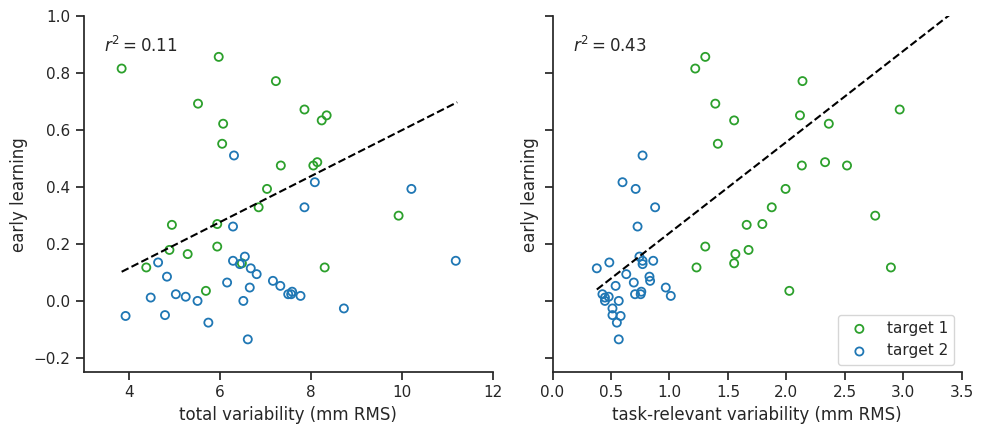

In [11]:
# colors: one per target
COLORS = {'shape1': 'tab:green', 'shape2': 'tab:blue'}
LABELS = {'shape1': 'target 1', 'shape2': 'target 2'}
groups = list(COLORS)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, x_col, x_lab , x_lim in zip(axes,
                            ['total_var_mmRMS', 'task_var_mmRMS'],
                            ['total variability (mm RMS)', 'task-relevant variability (mm RMS)'],
                            [[3, 12], [0, 3.5]]):
    for grp in groups:
        sub = data[data.group == grp]
        ax.scatter(sub[x_col], sub.early_learning, s=34, facecolor='none',
                   edgecolor=COLORS[grp], lw=1.3, label=LABELS[grp])
    fit = linregress(data[x_col], data.early_learning)
    x_line = np.linspace(data[x_col].min(), data[x_col].max(), 100)
    ax.plot(x_line, fit.intercept + fit.slope * x_line, '--', color='black', lw=1.5)
    ax.text(0.05, 0.9, '$r^2 = %.2f$' % fit.rvalue ** 2, transform=ax.transAxes)

    ax.set(xlabel=x_lab, ylabel='early learning')
    ax.set_ylim([-0.25, 1.0])
    ax.set_xlim(x_lim)

axes[1].legend()
plt.tight_layout()
plt.show()

## Prediction: trials to proficiency against the KL term

The theory predicts trials in proportion to the KL term (Eq. 10),
$m_2/m_1 = \mathrm{KL}_2/\mathrm{KL}_1$. With the KL at its leading term this is
$m \propto 1/v$, so on log axes the subjects should fall along a line of **slope 1**.

Wu et al. report a *learning level* $E$ that is the **average of the learning curve over
the first $M_0 = 800$ trials**. 

Every subject is assumed to follow the same curve shape, differing only in its trial scale
$\tau$,   
and trials to proficiency is where that curve reaches level $L = 0.9$.

**Simplest form.** Take the trial scale straight from the learning level,

$$\tau = \frac{M_0}{E}, \qquad m = \frac{M_0}{E}\,L.$$

Nothing is fitted here: $m$ is $1/E$ rescaled by a constant, so this is the raw data, and
every subject with $E > 0$ converts.

**Two saturating forms**, which add a shape but reduce to the constant-rate form at small
$E$. Their window averages are

$$\text{exponential:}\quad z = 1 - e^{-m/\tau}, \qquad
E = 1 - \frac{\tau}{M_0}\left(1 - e^{-M_0/\tau}\right),$$

$$\text{saturating power law } (\alpha = 1):\quad z = \frac{m}{m + \tau}, \qquad
E = 1 - \frac{\tau}{M_0}\ln\!\left(1 + \frac{M_0}{\tau}\right),$$

both inverted numerically for $\tau$. Both need $0 < E < 1$, so they drop the subjects
whose 800-trial mean is negative or past the rewarded deflection.

In [12]:
D_TARGET = 3.6     # target distance (mm)

# the KL at its leading term, in bits -- the task-relevant variance is the only input
data['kl'] = D_TARGET ** 2 / (2 * data['v'] * np.log(2))
print(data.groupby('group')['kl'].median())


group
shape1     2.354794
shape2    19.065839
Name: kl, dtype: float64


In [13]:
# Convert the learning level E into trials to reach proficiency L.  E is the *average* of
# the learning curve over the first M0 trials, not its value at M0, so each curve is
# inverted through its window average, E = (1 / M0) * integral of z(m) from 0 to M0.
M0 = 800           # window over which early learning is averaged
ALPHA = 1.0        # power-law exponent
PROFICIENCY = 0.9  # learning level that counts as proficient

def trials_rate(e):
    """Constant rate, tau = M0 / E."""
    return PROFICIENCY * M0 / e

def trials_exp(e):
    """Exponential, z = 1 - exp(-m / tau), so E = 1 - (tau / M0) (1 - exp(-M0 / tau))."""
    window_mean = lambda tau: 1 - (tau / M0) * (1 - np.exp(-M0 / tau))
    tau = np.array([brentq(lambda tau: window_mean(tau) - ei, 1e-3, 1e12)
                    for ei in np.atleast_1d(e)])
    return tau * np.log(1 / (1 - PROFICIENCY))

def trials_pow(e):
    """Saturating power law, 1 - z = (1 + m / tau)**(-alpha)."""
    if ALPHA == 1:
        window_mean = lambda tau: 1 - (tau / M0) * np.log1p(M0 / tau)
    else:
        window_mean = lambda tau: 1 - (tau / (M0 * (1 - ALPHA))) * ((1 + M0 / tau) ** (1 - ALPHA) - 1)
    tau = np.array([brentq(lambda tau: window_mean(tau) - ei, 1e-3, 1e12)
                    for ei in np.atleast_1d(e)])
    return tau * ((1 - PROFICIENCY) ** (-1 / ALPHA) - 1)

E = data.early_learning
pos = E > 0              # the constant rate only needs some progress
ok = (E > 0) & (E < 1)   # the saturating forms need a learning level inside (0, 1)

data.loc[pos, 'm_rate'] = trials_rate(E[pos])
data.loc[ok, 'm_exp'] = trials_exp(E[ok])
data.loc[ok, 'm_pow'] = trials_pow(E[ok])

print('converted: n = %d of %d  (%d with E <= 0, %d with E >= 1)'
      % (ok.sum(), len(data), (E <= 0).sum(), (E >= 1).sum()))
print('constant rate:  n = %d' % pos.sum())


converted: n = 50 of 61  (5 with E <= 0, 6 with E >= 1)
constant rate:  n = 56


In [14]:
# Group medians.  A median is well defined for every subject, so these use all 61 -- nobody
# is dropped -- and because the median commutes with a monotone transform, the point below is
# the median of the converted values rather than a distorted average of them.
# Error bars are percentile bootstraps, resampling subjects within each target.
N_BOOT = 5000
rng = np.random.default_rng(0)

group_pt = {}
for grp, sub in data.groupby('group'):
    v_med, e_med = sub.v.median(), sub.early_learning.median()
    draw = rng.choice(len(sub), size=(N_BOOT, len(sub)))
    v_ci = np.percentile(np.median(sub.v.values[draw], axis=1), [2.5, 97.5])
    e_ci = np.percentile(np.median(sub.early_learning.values[draw], axis=1), [2.5, 97.5])

    # both transforms are decreasing, so the upper bound on v (or E) gives the lower bound on x (or y)
    x = np.log2(D_TARGET ** 2 / (2 * np.array([v_med, v_ci[1], v_ci[0]]) * np.log(2)))
    pt = {'n': len(sub), 'x': x[0], 'xerr': [[x[0] - x[1]], [x[2] - x[0]]]}
    for col, convert in [('m_rate', trials_rate), ('m_exp', trials_exp), ('m_pow', trials_pow)]:
        y = np.log2(convert(np.array([e_med, e_ci[1], e_ci[0]])))
        pt[col] = {'y': y[0], 'yerr': [[y[0] - y[1]], [y[2] - y[0]]]}
    group_pt[grp] = pt

    print('%s:  n = %2d   median v = %.2f [%.2f, %.2f]   median E = %.3f [%.3f, %.3f]'
          % (LABELS[grp], len(sub), v_med, v_ci[0], v_ci[1], e_med, e_ci[0], e_ci[1]))

print('between-group slope:  ' + '   '.join(
    '%s %.2f' % (col, (group_pt['shape1'][col]['y'] - group_pt['shape2'][col]['y'])
                      / (group_pt['shape1']['x'] - group_pt['shape2']['x']))
    for col in ['m_rate', 'm_exp', 'm_pow']))


target 1:  n = 29   median v = 3.97 [2.76, 5.28]   median E = 0.487 [0.299, 0.672]
target 2:  n = 32   median v = 0.49 [0.32, 0.58]   median E = 0.059 [0.024, 0.125]
between-group slope:  m_rate 1.01   m_exp 1.20   m_pow 1.40


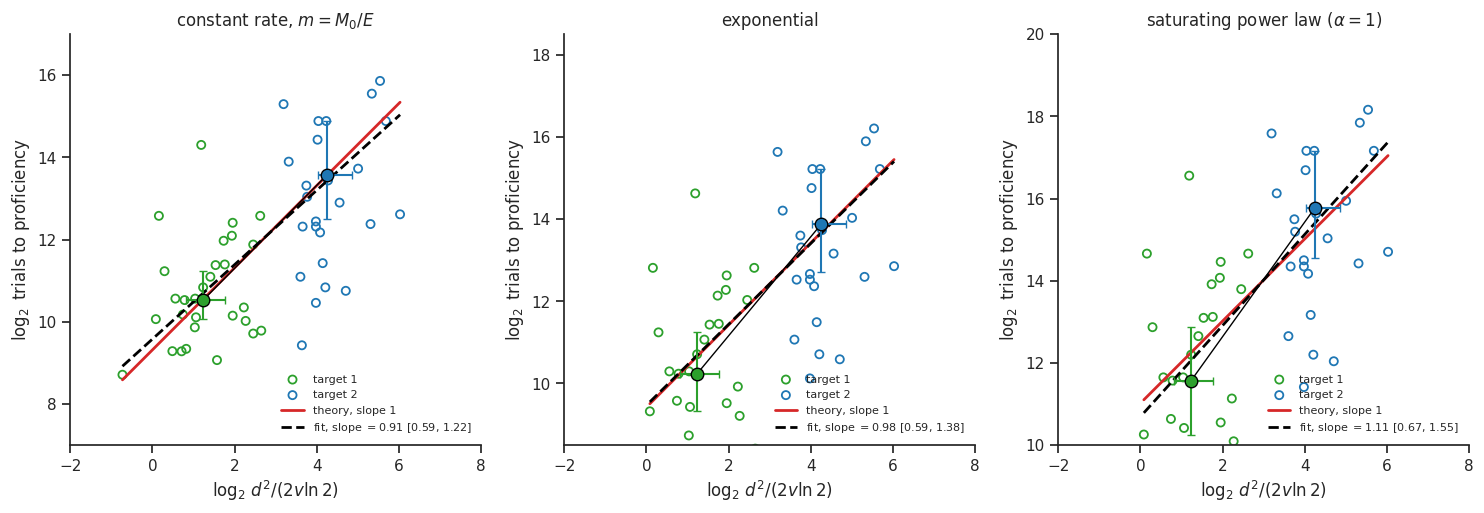

In [15]:
# log-log test: theory slope (1) vs the slope estimated by regression

# per panel: column, title, x and y limits.  The conversions differ by a constant factor,
# so each panel keeps the same span (slope 1 reads as 45 deg) but its own offset in y.
# The two slowest subjects sit well above the rest and fall off the top of every panel.
PANELS = [('m_rate', r'constant rate, $m = M_0 / E$', [-2, 8], [7, 17]),
          ('m_exp', 'exponential', [-2, 8], [8.5, 18.5]),
          ('m_pow', r'saturating power law ($\alpha = %g$)' % ALPHA, [-2, 8], [10, 20])]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (col, title, x_lim, y_lim) in zip(axes, PANELS):
    sel = data.dropna(subset=[col])
    for grp in groups:
        sub = sel[sel.group == grp]
        ax.scatter(np.log2(sub.kl), np.log2(sub[col]), s=34, facecolor='none',
                   edgecolor=COLORS[grp], lw=1.3, label=LABELS[grp])

    # group averages, from every subject including those the conversion above drops
    for grp in groups:
        pt = group_pt[grp]
        ax.errorbar(pt['x'], pt[col]['y'], xerr=pt['xerr'], yerr=pt[col]['yerr'],
                    fmt='o', ms=9, color=COLORS[grp], mec='black', mew=1.0,
                    capsize=3, lw=1.5, zorder=6)
    ax.plot([group_pt[g]['x'] for g in groups], [group_pt[g][col]['y'] for g in groups],
            '-', color='black', lw=1.0, zorder=5)

    x, y = np.log2(sel.kl), np.log2(sel[col])
    fit = linregress(x, y)
    t_crit = t.ppf(0.975, len(x) - 2)
    x_line = np.linspace(x.min(), x.max(), 100)

    # theory: trials proportional to KL, i.e. slope 1 (intercept is free, so anchor at the mean)
    ax.plot(x_line, x_line + (y.mean() - x.mean()), '-', color='tab:red', lw=2, zorder=4,
            label='theory, slope 1')
    # regression through the data
    ax.plot(x_line, fit.intercept + fit.slope * x_line, '--', color='black', lw=2, zorder=5,
            label='fit, slope $= %.2f$ [%.2f, %.2f]'
                  % (fit.slope, fit.slope - t_crit * fit.stderr, fit.slope + t_crit * fit.stderr))

    ax.set_xlabel(r'$\log_2 \, d^2 / (2 v \ln 2)$')
    ax.set_ylabel(r'$\log_2$ trials to proficiency')
    ax.set_xlim(x_lim)
    ax.set_ylim(y_lim)
    ax.set_xticks(np.arange(x_lim[0], x_lim[1] + 0.01, 2))
    ax.set_yticks(np.arange(np.ceil(y_lim[0] / 2) * 2, y_lim[1] + 0.01, 2))
    ax.set_aspect('equal', adjustable='box')   # same scale on x and y, so slope 1 reads as 45 deg
    ax.set_title(title)
    ax.legend(loc='lower right', frameon=False, fontsize=8)

plt.tight_layout()
plt.show()

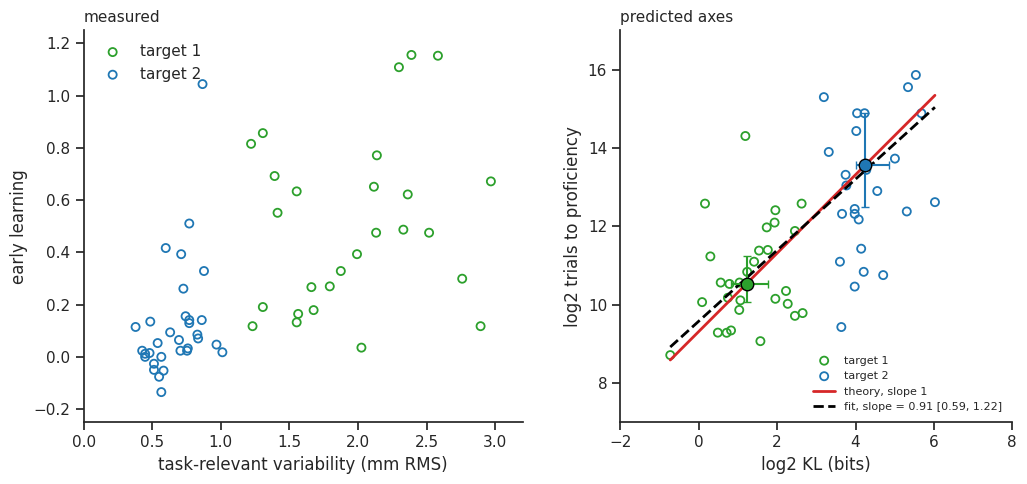

In [ ]:
# summary figure: the data as reported, and the same data on the predicted axes
# panels sized to match one panel of the 3-panel IBL figures, i.e. figsize=(16, 5) / 3
fig, axes = plt.subplots(1, 2, figsize=(2 * 16 / 3, 5))

# left panel: what Wu et al. measure -- early learning against task-relevant variability
ax = axes[0]
for grp in groups:
    sub = data[data.group == grp]
    ax.scatter(sub.task_var_mmRMS, sub.early_learning, s=34, facecolor='none',
               edgecolor=COLORS[grp], lw=1.3, label=LABELS[grp])

ax.set_xlabel('task-relevant variability (mm RMS)')
ax.set_ylabel('early learning')
ax.set_xlim([0, 3.2])          # the two upper-right outliers fall outside the frame
ax.set_ylim([-0.25, 1.25])
ax.legend(loc='upper left', frameon=False)
ax.set_title('measured', loc='left', fontsize=11)

# right panel: the same subjects on the axes the theory predicts, slope 1
ax = axes[1]
sel = data.dropna(subset=['m_rate'])
for grp in groups:
    sub = sel[sel.group == grp]
    ax.scatter(np.log2(sub.kl), np.log2(sub.m_rate), s=34, facecolor='none',
               edgecolor=COLORS[grp], lw=1.3, label=LABELS[grp])

for grp in groups:
    pt = group_pt[grp]
    ax.errorbar(pt['x'], pt['m_rate']['y'], xerr=pt['xerr'], yerr=pt['m_rate']['yerr'],
                fmt='o', ms=9, color=COLORS[grp], mec='black', mew=1.0,
                capsize=3, lw=1.5, zorder=6)

x, y = np.log2(sel.kl), np.log2(sel.m_rate)
fit = linregress(x, y)
t_crit = t.ppf(0.975, len(x) - 2)
x_line = np.linspace(x.min(), x.max(), 100)
ax.plot(x_line, x_line + (y.mean() - x.mean()), '-', color='tab:red', lw=2, zorder=4,
        label='theory, slope 1')
ax.plot(x_line, fit.intercept + fit.slope * x_line, '--', color='black', lw=2, zorder=5,
        label='fit, slope = %.2f [%.2f, %.2f]'
              % (fit.slope, fit.slope - t_crit * fit.stderr, fit.slope + t_crit * fit.stderr))

ax.set_xlabel('log2 KL (bits)')
ax.set_ylabel('log2 trials to proficiency')
ax.set_xlim([-2, 8])
ax.set_ylim([7, 17])
ax.set_xticks(np.arange(-2, 9, 2))
ax.set_yticks(np.arange(8, 18, 2))
ax.set_aspect('equal', adjustable='box')
ax.legend(loc='lower right', frameon=False, fontsize=8)
ax.set_title('predicted axes', loc='left', fontsize=11)

plt.tight_layout()
fig.savefig('wu_summary.pdf', dpi=300, bbox_inches='tight')
plt.show()